In [14]:
# CIRCUIT FOR QUANTUM STATE |00> + |11> (ENTANGLED STATE)

from qiskit import QuantumCircuit

qc = QuantumCircuit(2)  # create a circuit with 2 qubits (|q0q1> = |00> by default)

qc.h(0)         # apply Hadamard gate to qubit 0, putting it into superposition
qc.cx(0, 1)     # apply CNOT gate with qubit 0 as control and qubit 1 as target, creating entanglement

print(qc)   # print the circuit diagram

     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘


In [15]:
from qiskit.quantum_info import Statevector

state = Statevector.from_instruction(qc)

state

Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))


The above state means : [α00]
                        [α01]
                        [α10]
                        [α11]

                    =   [0.707]
                        [  0  ]
                        [  0  ]
                        [0.707]

                    =   [1/√2]
                        [  0 ]
                        [  0 ]
                        [1/√2]

                    = (1/√2) (|00> + |11>)
                    {50% chance of |00> and 50% chance of |11>}
                    It is a BELL STATE/ ENTANGLED STATE (cannot be written as product of two tensors)

dims=(2, 2) is a list explicitly defining the dimensions for each separate subsystem.
This state consists of 2 quantum subsystems, and each subsystem has dimension 2,
i.e, 
    q0 → 2-dimensional → |0>, |1>
    q1 → 2-dimensional → |0>, |1>

In [16]:
# CIRCUIT FOR QUANTUM STATE |00> + |11> (ENTANGLED STATE) WITH MEASUREMENT

from qiskit import QuantumCircuit

qc = QuantumCircuit(2, 2)   # Create a Quantum Circuit with 2 qubits (q0, q1) and 2 classical bits (c0, c1)

qc.h(0)         # apply Hadamard gate to qubit 0, putting it into superposition
qc.cx(0, 1)     # apply CNOT gate with qubit 0 as control and qubit 1 as target, creating entanglement

qc.measure([0, 1], [0, 1])  # measure both qubits and store the results in the classical bits
# measure [q0,q1] → [c0,c1]

print(qc)   # print the circuit diagram

     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 


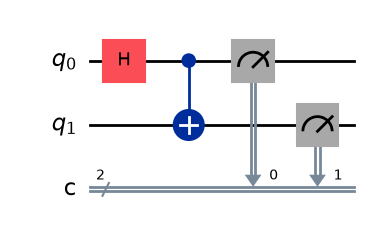

In [17]:
qc.draw("mpl")  # "mpl" means Matplotlib.

In [18]:
# RUNNING THE CIRCUIT ON A CLASSICAL SIMULATOR

from qiskit_aer import AerSimulator # a classical simulator that behaves like a quantum computer

simulator = AerSimulator()  # create a simulator instance to run the circuit on a classical computer

result = simulator.run(qc, shots=1000).result() # run the circuit on the simulator with 1000 shots (repetitions) and get the result

counts = result.get_counts()    # get the counts of the measurement results, which will show how many times each possible outcome was measured (e.g., '00', '01', '10', '11')

print(counts)   # print the counts of the measurement results, which will show how many times each possible outcome was measured 

{'11': 495, '00': 505}


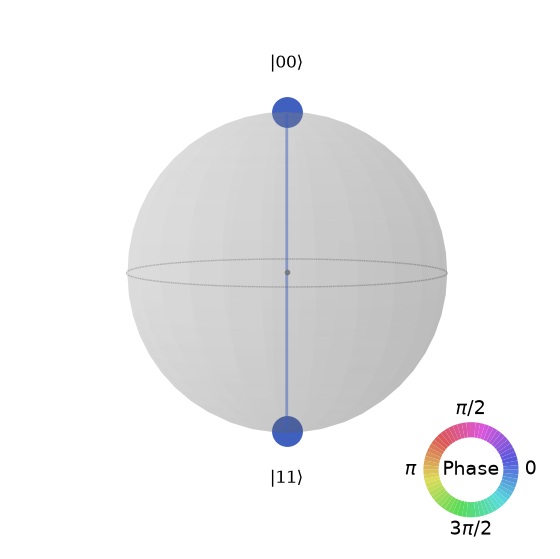

In [ ]:
# VISUALIZING THE QUANTUM STATE ON A QSPHERE

from qiskit.visualization import plot_state_qsphere

plot_state_qsphere(state)